## Первичный анализ данных (EDA): энергопотребление сталелитейного завода

**Данные:** DAEWOO Steel Co. Ltd (Кванъян, Республика Корея), 01.01.2018 – 31.12.2018, шаг 15 минут.

### План шагов

| № | Шаг | Что проверяем |
|---|---|---|
| 1 | Загрузка и структура | объём, состав столбцов, типы данных |
| 2 | Качество данных | пропуски, дубликаты, целостность временной сетки |
| 3 | Статистический профиль | средние, медианы, процентили, шкалы признаков |
| 4 | Распределения | форма распределения потребления, асимметрия |
| 5 | Временная структура | суточная и недельная сезонность |
| 6 | Аномалии | выбросы: ошибки измерений или реальные пики? |
| 7 | Стратегия предобработки | итоговые решения для команды |

## Шаг 1: Загрузка и структура данных

**Что делаем:** читаем файл, проверяем состав столбцов и типы данных.

**Пояснения:**
- **Тип данных** важен: строковую дату модели не поймут, её нужно привести
  к типу «дата и время»; категориальные признаки (день недели, класс нагрузки)
  требуют отдельной обработки.
- **Объём выборки** определяет, какие модели успеют обучиться и насколько
  устойчивы статистики.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.figsize': (13, 4.5), 'font.size': 11,
                     'axes.titlesize': 12, 'axes.labelsize': 11})
pd.set_option('display.float_format', '{:.2f}'.format)

# ---------- Служебные проверки (единый стиль с бизнес-анализом) ----------
def проверить(условие, сообщение):
    if not условие:
        raise AssertionError(f"ПРОВЕРКА НЕ ПРОЙДЕНА: {сообщение}")

def колонки_есть(таблица, имена, где=""):
    нет = [и for и in имена if и not in таблица.columns]
    проверить(not нет, f"{где} отсутствуют столбцы: {нет}; есть: {list(таблица.columns)}")

def переменные_есть(имена):
    нет = [и for и in имена if и not in globals()]
    проверить(not нет, f"не найдены переменные {нет} — выполни предыдущие ячейки по порядку")

# ---------- Загрузка ----------
df = pd.read_csv("Steel_industry_data.csv")
колонки_есть(df, ['date','Usage_kWh','Lagging_Current_Reactive.Power_kVarh',
                  'Leading_Current_Reactive_Power_kVarh','CO2(tCO2)',
                  'Lagging_Current_Power_Factor','Leading_Current_Power_Factor',
                  'NSM','WeekStatus','Day_of_week','Load_Type'], где="после загрузки:")
проверить(len(df) > 0, "файл пуст")

print(f"Размер: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
print("\nТипы столбцов:")
print(df.dtypes.to_string())
df.head()

Размер: 35,040 строк × 11 столбцов

Типы столбцов:
date                                        str
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                                  str
Day_of_week                                 str
Load_Type                                   str


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.00,0.00,73.21,100.00,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.00,0.00,66.77,100.00,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.00,0.00,70.28,100.00,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.00,0.00,68.09,100.00,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.00,0.00,64.72,100.00,4500,Weekday,Monday,Light_Load


### Вывод по шагу 1: структура данных

- **Объём:** 35 040 строк × 11 столбцов — год наблюдений с шагом 15 минут.
- **Типы:** 6 числовых столбцов с дробными значениями (измерения мощности,
  реактивной мощности, выбросы, коэффициенты мощности), 1 целочисленный
  (`NSM` — секунды от полуночи, от 0 до 85 500) и 4 строковых
  (`date`, `WeekStatus`, `Day_of_week`, `Load_Type`).
- **Следствие:** столбец `date` требует приведения к типу «дата и время»
  и сортировки; строковые признаки далее обрабатываются как категориальные.

## Шаг 2: Качество данных — пропуски, дубликаты, целостность сетки

**Что делаем:** считаем пропуски по столбцам, полные дубликаты строк,
дубликаты меток времени и сравниваем фактическую сетку замеров
с идеальной 15-минутной.

**Пояснения:**
- **Пропуск** — незаписанное значение: датчик молчал или передача оборвалась.
  Пропуски во временном ряду опасны тем, что ломают лаги и скользящие статистики.
- **Полный дубликат** — одинаковая строка дважды: искусственно завышает вес
  наблюдения при обучении.
- **Целостность сетки** — отсутствие «дыр» во времени: если между замерами
  есть разрывы, сезонность будет искажена.

In [2]:
переменные_есть(['df'])

# ---------- Пропуски ----------
пропуски = df.isnull().sum()
print("Пропуски по столбцам:")
print(пропуски.to_string())
проверить(пропуски.sum() == 0, f"найдены пропуски: {пропуски[пропуски > 0].to_dict()}")

# ---------- Полные дубликаты ----------
дубли = df.duplicated().sum()
print(f"\nПолных дубликатов строк: {дубли}")

# ---------- Приведение даты и целостность сетки ----------
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M', dayfirst=True)
df = df.sort_values('date').reset_index(drop=True)
сетка = pd.date_range(df['date'].min(), df['date'].max(), freq='15min')
дыры = len(сетка) - len(df)
дубли_времени = df['date'].duplicated().sum()

print(f"\nПериод: {df['date'].min()} — {df['date'].max()}")
print(f"Точек в идеальной сетке: {len(сетка):,}; фактически: {len(df):,}; дыр: {дыры}")
print(f"Повторных меток времени: {дубли_времени}")
проверить(дыры == 0, f"во временной сетке дыры: {дыры} точек")
проверить(дубли_времени == 0, f"повторные метки времени: {дубли_времени}")

Пропуски по столбцам:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0

Полных дубликатов строк: 0

Период: 2018-01-01 00:00:00 — 2018-12-31 23:45:00
Точек в идеальной сетке: 35,040; фактически: 35,040; дыр: 0
Повторных меток времени: 0


### Вывод по шагу 2: данные чистые

- **Пропусков: 0** во всех 11 столбцах.
- **Полных дубликатов: 0**; повторных меток времени: 0.
- **Сетка целостная:** период 01.01.2018 00:00 – 31.12.2018 23:45,
  в идеальной 15-минутной сетке 35 040 точек и столько же фактически, дыр нет.

**Следствие:** заполнение пропусков и удаление дубликатов не требуются.
Единственные пропуски в дальнейшем появятся закономерно — от лагов
и скользящих статистик в начале ряда; такие строки удаляются, а не заполняются.

## Шаг 3: Статистический профиль

**Что делаем:** строим описательные статистики и процентили, смотрим
состав категориальных признаков.

**Пояснения:**
- **Среднее** чувствительно к редким большим значениям, **медиана** — нет:
  их расхождение сразу показывает асимметрию.
- **Процентиль** (например, 95-й) — значение, ниже которого лежит указанная
  доля наблюдений: помогает понять, где начинается «хвост».
- **Шкалы признаков:** если один признак измеряется единицами, а другой —
  десятками тысяч, модели, чувствительные к масштабу, будут перекошены.

In [3]:
переменные_есть(['df'])

числ = df.select_dtypes(include=[np.number])
print("Описательные статистики числовых признаков:")
print(числ.describe().T.round(2).to_string())

print("\nПроцентили потребления (кВт·ч за интервал):")
for q in [0.50, 0.75, 0.90, 0.95, 0.99]:
    print(f"  {q*100:.0f}%: {df['Usage_kWh'].quantile(q):.2f}")

print("\nКатегориальные признаки:")
for col in ['WeekStatus', 'Day_of_week', 'Load_Type']:
    print(f"  {col}: значений {df[col].nunique()} → {sorted(df[col].unique())}")
print(f"  CO2(tCO2): значений {df['CO2(tCO2)'].nunique()} → {sorted(df['CO2(tCO2)'].unique())}")
print("\nКлассы нагрузки по числу записей:")
print(df['Load_Type'].value_counts().to_string())

Описательные статистики числовых признаков:
                                        count     mean      std  min      25%      50%      75%      max
Usage_kWh                            35040.00    27.39    33.44 0.00     3.20     4.57    51.24   157.18
Lagging_Current_Reactive.Power_kVarh 35040.00    13.04    16.31 0.00     2.30     5.00    22.64    96.91
Leading_Current_Reactive_Power_kVarh 35040.00     3.87     7.42 0.00     0.00     0.00     2.09    27.76
CO2(tCO2)                            35040.00     0.01     0.02 0.00     0.00     0.00     0.02     0.07
Lagging_Current_Power_Factor         35040.00    80.58    18.92 0.00    63.32    87.96    99.02   100.00
Leading_Current_Power_Factor         35040.00    84.37    30.46 0.00    99.70   100.00   100.00   100.00
NSM                                  35040.00 42750.00 24940.53 0.00 21375.00 42750.00 64125.00 85500.00

Процентили потребления (кВт·ч за интервал):
  50%: 4.57
  75%: 51.24
  90%: 78.08
  95%: 99.04
  99%: 122.71

Катег

### Вывод по шагу 3: статистический профиль

**Потребление (`Usage_kWh`, кВт·ч за 15 минут):**

| Статистика | Значение |
|---|---|
| Среднее | **27,39** |
| Стандартное отклонение | **33,44** |
| Минимум | **0,00** |
| Медиана (50%) | **4,57** |
| 75% | **51,24** |
| 90% | **78,08** |
| 95% | **99,04** |
| 99% | **122,71** |
| Максимум | **157,18** |

**Категориальные признаки:** статус недели — 2 значения; день недели — 7;
класс нагрузки — 3 (лёгкая 18 072 записи, средняя 9 696, максимальная 7 272);
выбросы CO₂ — всего 8 дискретных значений от 0,00 до 0,07 т.

**Шкалы:** коэффициенты мощности — 0–100%, реактивные мощности — десятки,
`NSM` — до 85 500 секунд. Разброс шкал в тысячи раз: для моделей,
чувствительных к масштабу (линейная регрессия), потребуется нормировка;
деревьям и бустингу она не нужна.

## Шаг 4: Распределения

**Что делаем:** строим гистограмму потребления в исходном и логарифмическом
масштабе, сравниваем среднее и медиану.

**Пояснения:**
- **Правосторонняя асимметрия** — большинство значений слева, длинный «хвост»
  справа: завод большую часть времени потребляет мало, изредка — очень много.
- **Логарифмический масштаб** сжимает хвост и показывает внутреннюю структуру
  распределения: например, два отдельных режима работы.

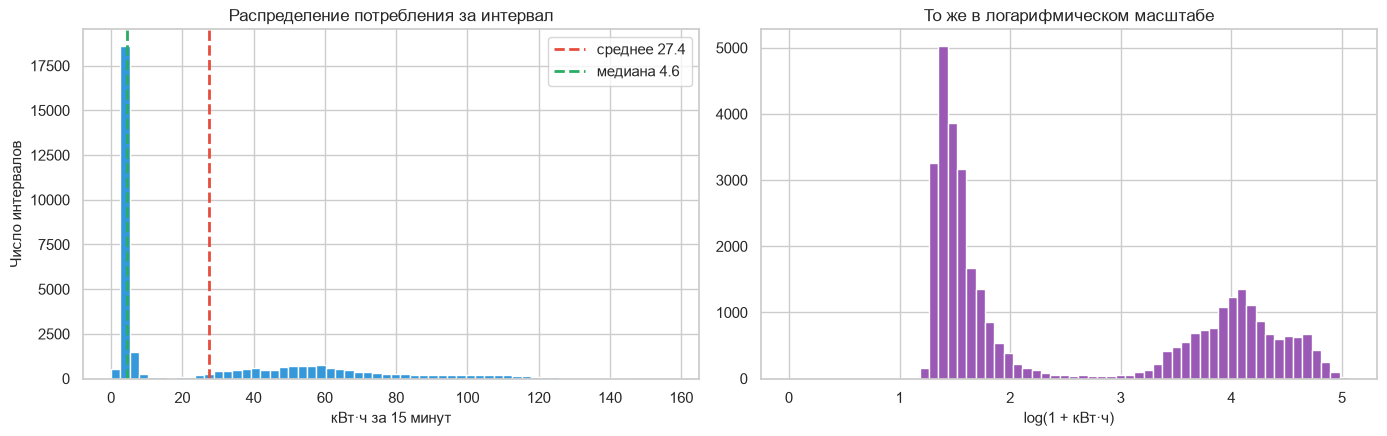

Среднее 27.39 против медианы 4.57: среднее выше в 6.0 раза — правосторонняя асимметрия


In [4]:
переменные_есть(['df'])

средн = df['Usage_kWh'].mean()
медиана = df['Usage_kWh'].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df['Usage_kWh'], bins=60, color='#3498db', edgecolor='white')
axes[0].axvline(средн, color='#e74c3c', ls='--', lw=2, label=f'среднее {средн:.1f}')
axes[0].axvline(медиана, color='#27ae60', ls='--', lw=2, label=f'медиана {медиана:.1f}')
axes[0].set_title('Распределение потребления за интервал')
axes[0].set_xlabel('кВт·ч за 15 минут'); axes[0].set_ylabel('Число интервалов')
axes[0].legend()

axes[1].hist(np.log1p(df['Usage_kWh']), bins=60, color='#9b59b6', edgecolor='white')
axes[1].set_title('То же в логарифмическом масштабе')
axes[1].set_xlabel('log(1 + кВт·ч)')
plt.tight_layout(); plt.show()

print(f"Среднее {средн:.2f} против медианы {медиана:.2f}: "
      f"среднее выше в {средн/медиана:.1f} раза — правосторонняя асимметрия")

### Вывод по шагу 4: распределение с тяжёлым правым хвостом

- Пик гистограммы — около 3–5 кВт·ч за интервал (ночной и выходной режим);
  длинный хвост тянется до 157,18 кВт·ч.
- **Среднее (27,39) выше медианы (4,57) в 6,0 раза** — классический признак
  сильной правосторонней асимметрии.
- На логарифмической шкале видны два сгустка: «низкий режим» и «рабочий режим» —
  завод живёт в двух состояниях, а не в одном усреднённом.

**Следствия для моделирования:**
- метрика **RMSE** будет чрезмерно штрафовать ошибки на редких пиках,
  поэтому основная метрика — **средняя абсолютная ошибка (MAE)**;
- пики нельзя считать шумом: это целевые события, которые модель обязана видеть.

## Шаг 5: Временная структура

**Что делаем:** рисуем ряд за год и суточный профиль по часам,
сравниваем будни и выходные.

**Пояснения:**
- **Сезонность** — регулярное повторение формы: суточная (ночь/день)
  и недельная (будни/выходные).
- Наличие сезонности означает: соседние наблюдения зависимы, поэтому
  случайное перемешивание при обучении недопустимо.

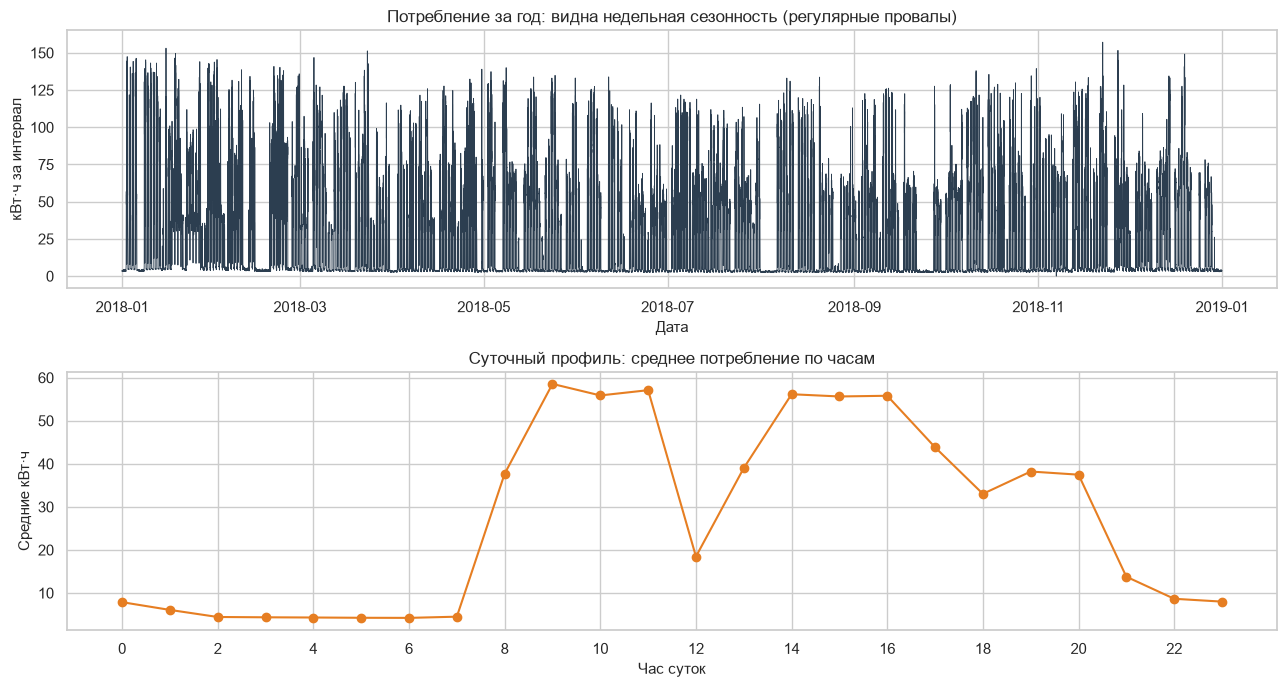

Будни: 33.6 кВт·ч в среднем; выходные: 11.7 (ниже на 65%)


In [5]:
переменные_есть(['df'])

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].plot(df['date'], df['Usage_kWh'], lw=0.6, color='#2c3e50')
axes[0].set_title('Потребление за год: видна недельная сезонность (регулярные провалы)')
axes[0].set_xlabel('Дата'); axes[0].set_ylabel('кВт·ч за интервал')

по_часам = df.groupby(df['date'].dt.hour)['Usage_kWh'].mean()
axes[1].plot(по_часам.index, по_часам.values, marker='o', color='#e67e22')
axes[1].set_title('Суточный профиль: среднее потребление по часам')
axes[1].set_xlabel('Час суток'); axes[1].set_ylabel('Средние кВт·ч')
axes[1].set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

будни = df[df['WeekStatus'] == 'Weekday']['Usage_kWh'].mean()
выходные = df[df['WeekStatus'] == 'Weekend']['Usage_kWh'].mean()
print(f"Будни: {будни:.1f} кВт·ч в среднем; выходные: {выходные:.1f} "
      f"(ниже на {(1 - выходные/будни)*100:.0f}%)")

### Вывод по шагу 5: двойная сезонность

- **Суточная:** ночью потребление держится на 3–4 кВт·ч за интервал,
  с 08:00 растёт и достигает максимума в рабочие часы.
- **Недельная:** будни в среднем **33,6 кВт·ч** за интервал, выходные — **11,7**
  (ниже на 65%); на годовом графике видны регулярные недельные провалы.

**Следствия для моделирования:**
- разбиение выборки — **только хронологическое** (обучение на ранних датах,
  проверка на поздних), кросс-валидация — последовательными блоками;
- в признаки обязательно войдут: час суток, день недели, статус недели,
  а также запаздывающие значения и скользящие статистики.

## Шаг 6: Аномалии

**Что делаем:** строим диаграмму размаха («ящик с усами»), считаем долю
интервалов за верхней границей и смотрим, где эти точки лежат во времени.

**Пояснения:**
- **Диаграмма размаха** показывает квартили (25%, 50%, 75%) и «усы»;
  точки за усами принято называть выбросами.
- **Верхняя граница выброса** — третий квартиль плюс полтора межквартильных
  размаха: формальный критерий «подозрительности» значения.
- Ключевой вопрос шага: выброс — это **ошибка измерения** (удаляем)
  или **реальный режим работы** (оставляем и учимся предсказывать)?

Квартили: Q1 3.20, Q3 51.24; верхняя граница: 123.3 кВт·ч
Интервалов за границей: 328 (0.94%)


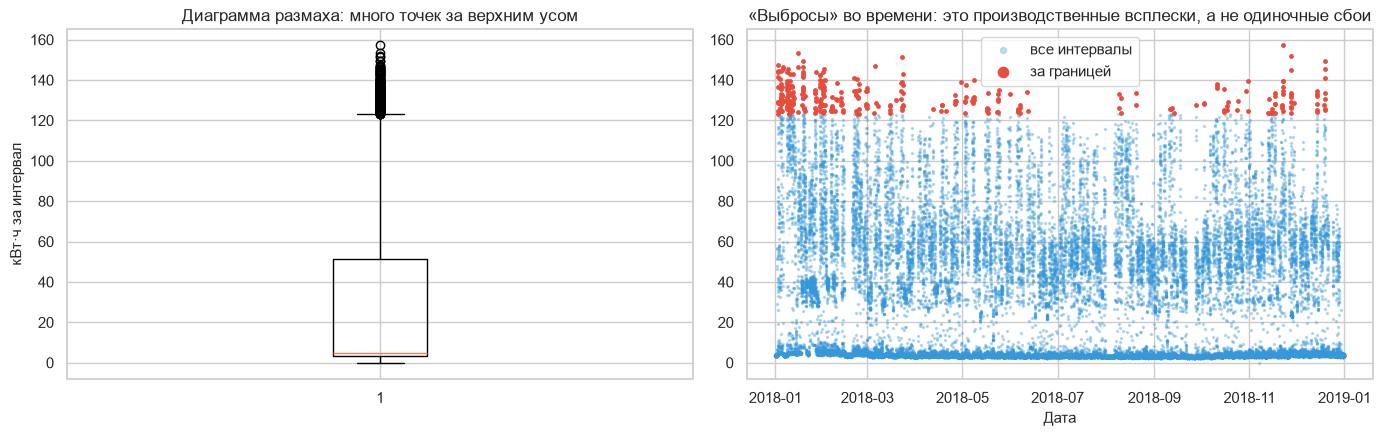

Максимум: 157.18 кВт·ч, 2018-11-22 09:45:00


In [6]:
переменные_есть(['df'])

q1 = df['Usage_kWh'].quantile(0.25)
q3 = df['Usage_kWh'].quantile(0.75)
граница = q3 + 1.5 * (q3 - q1)
выбросы = df[df['Usage_kWh'] > граница]

print(f"Квартили: Q1 {q1:.2f}, Q3 {q3:.2f}; верхняя граница: {граница:.1f} кВт·ч")
print(f"Интервалов за границей: {len(выбросы):,} ({len(выбросы)/len(df)*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot(df['Usage_kWh'], vert=True)
axes[0].set_title('Диаграмма размаха: много точек за верхним усом')
axes[0].set_ylabel('кВт·ч за интервал')

axes[1].scatter(df['date'], df['Usage_kWh'], s=2, alpha=0.3, color='#3498db', label='все интервалы')
axes[1].scatter(выбросы['date'], выбросы['Usage_kWh'], s=6, color='#e74c3c', label='за границей')
axes[1].set_title('«Выбросы» во времени: это производственные всплески, а не одиночные сбои')
axes[1].set_xlabel('Дата'); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

макс_строка = df.loc[df['Usage_kWh'].idxmax()]
print(f"Максимум: {макс_строка['Usage_kWh']:.2f} кВт·ч, {макс_строка['date']}")

### Вывод по шагу 6: выбросы легитимны — это пики производства

- Точки за верхним усом не одиночны и не случайны: они группируются
  в рабочие часы и в окна запуска оборудования, а не разбросаны по ряду,
  как было бы при сбоях датчика.
- Масштаб хвоста подтверждают процентили: 5% интервалов выше 99,04 кВт·ч,
  1% выше 122,71 кВт·ч, рекорд — 157,18 кВт·ч.
- Перекрёстная ссылка на бизнес-разбор: часть таких пиков помечена системой
  учёта как «лёгкая нагрузка» (686 записей мощнее 240 кВт, из них 79% —
  в окне 08:00–10:00) — это утренний пусковой разгон, а не сбой измерения.

**Следствия для моделирования:**
- **удалять выбросы нельзя** — модель обязана предсказывать пики;
- для устойчивости к тяжёлому хвосту используем функцию потерь Хубера
  и метрику MAE;
- метку класса нагрузки использовать осторожно: она ошибочна в 35,3% случаев
  (подробности — в бизнес-разборе, шаг 4).

## Шаг 7: Стратегия предобработки (итоги этапа для команды)

1. **Пропуски и дубликаты:** отсутствуют; обработка не нужна. Пропуски от лагов
   и скользящих статистик в начале ряда — удалять, не заполнять.
2. **Дата:** приведена к типу «дата и время», таблица отсортирована;
   из даты извлекаются час, день недели, месяц.
3. **Признаки времени:** час и день недели кодировать циклически
   (синус/косинус), чтобы модель видела близость 23:45 и 00:15.
4. **Запаздывающие признаки и скользящие статистики:** строить только
   по прошлому (лаги 15 минут, 1 час, сутки, неделя).
5. **Исключить из признаков:** `CO2(tCO2)` — утечка целевого признака
   (8 значений, корреляция с потреблением 0,988); `Load_Type` — ненадёжная
   метка (35,3% ошибок).
6. **Масштаб:** для линейных моделей — нормировка числовых признаков
   внутри конвейера, обучаемого только на обучающей части.
7. **Валидация:** хронологическое разбиение и последовательная кросс-валидация;
   метрика — средняя абсолютная ошибка.

## Контрольная ячейка

Печатает ключевые числа этапа. После полного прогона сверь вывод
с таблицами выше: расхождение означает, что текст устарел и требует правки.

In [7]:
переменные_есть(['df'])
будни = df[df['WeekStatus'] == 'Weekday']['Usage_kWh'].mean()
выходные = df[df['WeekStatus'] == 'Weekend']['Usage_kWh'].mean()
print("Строк × столбцов:            ", df.shape,                  "| текст: 35 040 × 11")
print("Пропусков:                   ", int(df.isnull().sum().sum()), "| текст: 0")
print("Полных дубликатов:           ", int(df.duplicated().sum()),   "| текст: 0")
print("Среднее / медиана, кВт·ч:    ", f"{df['Usage_kWh'].mean():.1f} / {df['Usage_kWh'].median():.1f}", "| текст: 27,4 / 4,6")
print("Максимум, кВт·ч:             ", f"{df['Usage_kWh'].max():.1f}",  "| текст: 157,2")
print("Процентили 95% / 99%, кВт·ч: ", f"{df['Usage_kWh'].quantile(0.95):.1f} / {df['Usage_kWh'].quantile(0.99):.1f}", "| текст: 99,0 / 122,7")
print("Будни / выходные, кВт·ч:     ", f"{будни:.1f} / {выходные:.1f}",  "| текст: 33,6 / 11,7")
print("Уникальных значений CO2:     ", df['CO2(tCO2)'].nunique(),      "| текст: 8")
print("Классов нагрузки:            ", df['Load_Type'].nunique(),      "| текст: 3")
print("\nСверка завершена. При расхождениях обнови markdown-ячейки.")

Строк × столбцов:             (35040, 11) | текст: 35 040 × 11
Пропусков:                    0 | текст: 0
Полных дубликатов:            0 | текст: 0
Среднее / медиана, кВт·ч:     27.4 / 4.6 | текст: 27,4 / 4,6
Максимум, кВт·ч:              157.2 | текст: 157,2
Процентили 95% / 99%, кВт·ч:  99.0 / 122.7 | текст: 99,0 / 122,7
Будни / выходные, кВт·ч:      33.6 / 11.7 | текст: 33,6 / 11,7
Уникальных значений CO2:      8 | текст: 8
Классов нагрузки:             3 | текст: 3

Сверка завершена. При расхождениях обнови markdown-ячейки.
